![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

**This notebook is your report.** It is read on its own, by someone who has not seen notebooks 01 and 02, so it needs the prose as much as the code: the question, the final model, how good it is, where it fails, what drives it, and how far to trust it.

> **Done when:** someone who has never met your project can read this top to bottom and understand what you predicted, how well, compared with what, and where the model should not be used.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [20]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.metrics import fbeta_score, recall_score, precision_score, f1_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. The question and the final model

The framing from notebook 01 and the choice from notebook 02, in a few sentences. Then refit the final pipeline on the whole training set.


**The question:** Which current customers are likely to churn, so the retention team can contact them with an offer before they leave?

- **Target:** `Churn`, positive class = `Yes` (1). About 26.5% of customers churn.
- **Metric: F2.** Missing a churner (lost customer) costs more than sending an offer to someone who would have stayed, so recall is weighted above precision. Unlike recall alone, F2 cannot be gamed by flagging everyone: the "always Yes" baseline only reaches F2 = 0.64.
- **Data preparation (notebook 01):** `TotalCharges` converted to numbers (11 blanks = 0, all new customers); `customerID` dropped; stratified 80/20 split with a fixed seed.

**The final model (notebook 02).** Logistic regression (`C=0.1`, `class_weight="balanced"`) behind a `ColumnTransformer` (scaled numeric columns, one-hot categorical columns), wrapped in `TunedThresholdClassifierCV` so the decision threshold (= 0.32) is chosen by F2 on the training folds.

It was chosen over a tuned HistGradientBoosting model because the two were tied under nested cross-validation (F2 0.749 +- 0.005 vs 0.742 +- 0.009, a gap smaller than the fold spread). Logistic regression is simpler, more stable across folds, and its coefficients can be read by the retention team.

Below, the same pipeline is rebuilt and refitted on the whole training set and its cross-validated estimate is recomputed so this notebook stands on its own.

In [2]:
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.3f}")

Train: (5634, 19), churn rate 0.265
Test:  (1409, 19), churn rate 0.265


In [4]:
# The final model chosen and fitted on the full training set in notebook 02
bundle = joblib.load(MODELS / "final_model.joblib")
final_model = bundle["model"] 
threshold = bundle["threshold"]
f2 = SCORING["f2"]

print(final_model.estimator_)
print(f"Tuned threshold: {threshold:.3f}")

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(drop='if_binary',
        

In [6]:
cv_res = cross_validate(final_model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
cv_summary = pd.DataFrame({
    m: [cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std()] for m in SCORING
    }, index=["CV mean", "CV std"]).round(3)
cv_summary

,f2,average_precision,recall,precision,f1,accuracy
CV mean,0.749,0.652,0.917,0.433,0.588,0.659
CV std,0.005,0.029,0.009,0.011,0.009,0.015


---
## 2. Test once

The final model on the test set, **once**. Compare the score with the cross-validated estimate and with the baseline. If it is much worse than the estimate, say what that tells you.

In [ ]:
always_no = DummyClassifier(strategy="most_frequent")
always_no.fit(X_train, y_train)

always_yes = DummyClassifier(strategy="constant", constant=1)
always_yes.fit(X_train, y_train)

models = {
    'Always "No"': always_no,
    'Always "Yes"': always_yes,
    'LogisticRegression (C=0.1)': final_model,
}

rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({
        'model': name,
        'f2': fbeta_score(y_test, y_pred, beta=2),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'accuracy': accuracy_score(y_test, y_pred),
    })

test_results = pd.DataFrame(rows).set_index("model").round(3)
test_results

,f2,recall,precision,f1,accuracy
model,,,,,
"Always ""No""",0.000,0.00,0.000,0.000,0.735
"Always ""Yes""",0.644,1.00,0.265,0.420,0.265
LogisticRegression (C=0.1),0.756,0.92,0.442,0.597,0.670


In [ ]:
# Cross-validated estimate on the training set, same as notebook 02
cv_res = cross_validate(final_model, X_train, y_train, cv=CV, scoring=SCORING)

model_test = test_results.loc['LogisticRegression (C=0.1)']
baseline_test = test_results.loc['Always "Yes"']

rows = []
for metric in ['f2', 'recall', 'precision', 'f1', 'accuracy']:
    s = cv_res[f"test_{metric}"]
    rows.append({
        "metric": metric,
        "test": model_test[metric],
        "CV mean": s.mean(),
        "CV std": s.std(),
        'Baseline (always "Yes")': baseline_test[metric],
    })

comparison = pd.DataFrame(rows).set_index("metric").round(3)
comparison

,test,CV mean,CV std,"Baseline (always ""Yes"")"
metric,,,,
f2,0.756,0.749,0.005,0.644
recall,0.920,0.917,0.009,1.000
precision,0.442,0.433,0.011,0.265
f1,0.597,0.588,0.009,0.420
accuracy,0.670,0.659,0.015,0.265


---
## 3. Where it goes wrong

Classification: the confusion matrix and the per-class results, at your chosen threshold. Regression: the residuals, and where they are largest. Look at a few of the worst predictions and say what they have in common.

              precision    recall  f1-score   support

    No churn       0.95      0.58      0.72      1035
       Churn       0.44      0.92      0.60       374

    accuracy                           0.67      1409
   macro avg       0.70      0.75      0.66      1409
weighted avg       0.82      0.67      0.69      1409

Missed churners: 30
False alarms: 435
Flagged: 55.3%


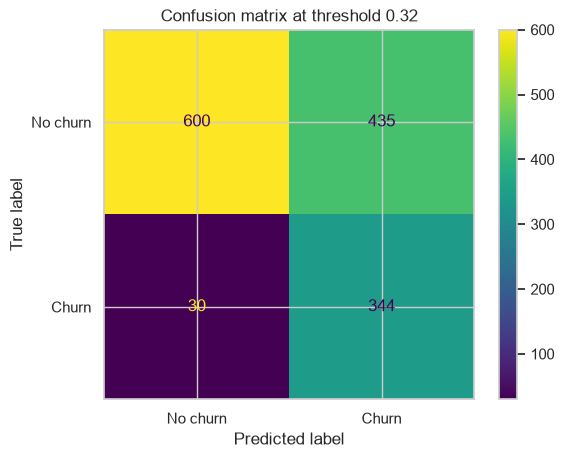

In [15]:
# Classification per class results & confusion matrix at chosen threshold
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

print(f"Missed churners: {int(((y_pred == 0) & (y_test == 1)).sum())}")
print(f"False alarms: {int(((y_pred == 1) & (y_test == 0)).sum())}")
print(f"Flagged: {y_pred.mean() * 100:.1f}%")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"])
plt.title(f"Confusion matrix at threshold {threshold:.2f}")
plt.show()

On the 1409 test churners, the model finds **344 of the 374 actual churns** (recall 0.92) and raises 435 false alarms among 1035 non-churners (precision 0.95). That is in line with the cross-validated estimates, the test set confirms the choices.

In [ ]:
# Worst predictions 
y_proba = final_model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["churn"] = y_test
results["proba"] = y_proba
results["pred"] = y_pred

missed = results[(results["churn"] == 1) & (results["pred"] == 0)]
false_alarms = results[(results["churn"] == 0) & (results["pred"] == 1)]

cols = ["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges", "OnlineSecurity", "TechSupport", "proba"]

print("Missed churners with the lowest churn probability:")
display(missed.sort_values("proba").head(10)[cols].round(3))

print("False alarms with the highest churn probability:")
display(false_alarms.sort_values("proba", ascending=False).head(10)[cols].round(3))

Missed churners with the lowest churn probability:


,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,OnlineSecurity,TechSupport,proba
268,59,Two year,No,Mailed check,19.35,No internet service,No internet service,0.015
4642,65,Two year,DSL,Bank transfer (automatic),74.80,Yes,Yes,0.044
4418,58,One year,DSL,Credit card (automatic),60.30,Yes,No,0.050
5946,42,One year,DSL,Credit card (automatic),73.90,Yes,Yes,0.088
3788,54,Two year,Fiber optic,Bank transfer (automatic),109.75,Yes,Yes,0.114
2244,34,One year,DSL,Mailed check,64.40,Yes,Yes,0.138
6945,70,Two year,Fiber optic,Bank transfer (automatic),98.30,No,No,0.153
6680,48,Two year,Fiber optic,Mailed check,95.50,No,Yes,0.160
5581,68,Two year,Fiber optic,Electronic check,113.15,Yes,Yes,0.160
3040,71,Two year,Fiber optic,Credit card (automatic),108.60,No,Yes,0.165


False alarms with the highest churn probability:


,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,OnlineSecurity,TechSupport,proba
935,4,Month-to-month,Fiber optic,Electronic check,83.25,No,No,0.912
345,1,Month-to-month,Fiber optic,Electronic check,72.10,No,No,0.904
4077,14,Month-to-month,Fiber optic,Electronic check,95.80,No,No,0.897
3469,15,Month-to-month,Fiber optic,Electronic check,91.50,No,No,0.891
2519,2,Month-to-month,Fiber optic,Electronic check,91.45,No,No,0.887
6096,1,Month-to-month,Fiber optic,Electronic check,70.20,No,No,0.885
6837,6,Month-to-month,Fiber optic,Electronic check,79.70,No,No,0.885
1095,1,Month-to-month,Fiber optic,Electronic check,80.55,No,No,0.879
3981,8,Month-to-month,Fiber optic,Electronic check,85.20,No,No,0.879
4173,12,Month-to-month,Fiber optic,Electronic check,86.55,No,No,0.877


In [19]:
churners = results[results["churn"] == 1]

for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"Recall by {col}:")
    print(churners.groupby(col)["pred"].mean().round(2))
    print()

print("Median tenure of churners, caught (1) vs missed (0):")
print(churners.groupby("pred")["tenure"].median())

Recall by Contract:
Contract
Month-to-month    0.98
One year          0.65
Two year          0.10
Name: pred, dtype: float64

Recall by InternetService:
InternetService
DSL            0.86
Fiber optic    0.95
No             0.72
Name: pred, dtype: float64

Recall by PaymentMethod:
PaymentMethod
Bank transfer (automatic)    0.83
Credit card (automatic)      0.76
Electronic check             0.98
Mailed check                 0.88
Name: pred, dtype: float64

Median tenure of churners, caught (1) vs missed (0):
pred
0    56.0
1     8.0
Name: tenure, dtype: float64


The model learned that customers on long contracts with long tenure usually stay. So when one of them does leave, the model doesn’t see it coming. We can see this in low recall for long contracts (0.10) and higher tenure among the missed churners (56 months).

---
## 4. What drives the predictions

Permutation importance on the test set, or an equivalent. Strongly related features share their importance, so read the ranking with care, and translate it into business terms.

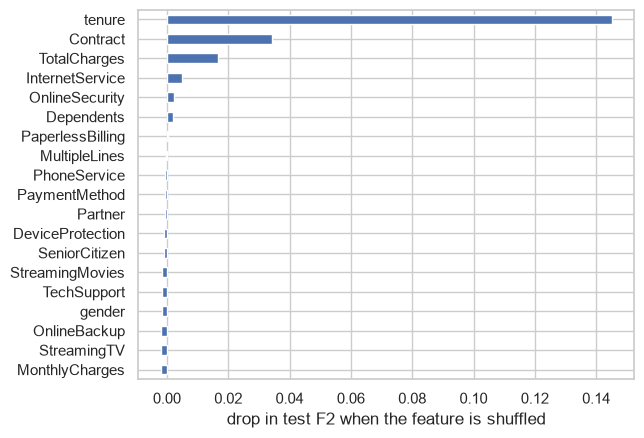

tenure             0.145
Contract           0.034
TotalCharges       0.017
InternetService    0.005
OnlineSecurity     0.002
dtype: float64

In [21]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING["f2"], n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh()
plt.xlabel("drop in test F2 when the feature is shuffled")
plt.show()

importance.sort_values(ascending=False).head(5).round(3)

## What drives the predictions

Permutation importance on the test set, scored with F2:

| Feature | Drop in test F2 when shuffled |
|---|---|
| tenure | 0.145 |
| Contract | 0.034 |
| TotalCharges | 0.017 |
| InternetService | 0.005 |
| OnlineSecurity | 0.002 |

- **Tenure is by far the most important feature.** Shuffling it drops F2 from 0.756 to about 0.61, below the always-"Yes" baseline (0.644). How long someone has been a customer is the main thing the model uses.
- **Contract** and **TotalCharges** are the only other clear contributors. All other features have an importance close to 0. The small negative values are noise, not harmful features.

**Reading the ranking with care:** strongly related features share their importance.
- `tenure` and `TotalCharges` are highly correlated (0.83 in notebook 01), which is the main driver.
- `PaymentMethod`, `InternetService` and `TechSupport` had a strong link with churn in notebook 01, but they score close to 0 here. Their information is already contained in other features: electronic-check customers are mostly new and month-to-month (captured by `tenure` and `Contract`), and the internet add-ons and charges overlap with each other.
- An importance close to 0 therefore means that they add nothing beyond the other features, not  that they are unrelated to churn.

**In business terms:**
- **The first months are the riskiest.** New customers churn far more than long-term ones, so onboarding and an early check-in are the main retention opportunity.
- **Month-to-month contracts are the biggest risk group.** Offers that move customers to a one- or two-year contract are the most direct lever.

---
## 5. Save, reload, predict

Save the fitted pipeline (and the threshold) with `joblib` into `models/`, reload it, and predict for a few new rows. This is your demo on Friday.

In [24]:
# Load the saved model
saved = joblib.load(MODELS / "final_model.joblib")
loaded_model = saved["model"]

# Pick 5 customers the model has never seen
demo = X_test.head(5).copy()

# Ask the model
demo["churn_probability"] = loaded_model.predict_proba(X_test.head(5))[:, 1].round(2)
demo["prediction"] = loaded_model.predict(X_test.head(5))

# What really happened
demo["actual"] = y_test.head(5).values

demo[["tenure", "Contract", "MonthlyCharges", "churn_probability", "prediction", "actual"]]

,tenure,Contract,MonthlyCharges,churn_probability,prediction,actual
5532,31,Two year,20.90,0.05,0,0
5173,4,Month-to-month,44.80,0.62,1,0
7010,1,Month-to-month,74.45,0.90,1,1
6507,58,Month-to-month,93.40,0.41,1,1
5985,57,One year,74.60,0.11,0,0


---
## 6. Conclusions and limitations

Would you use this model, and for what? Where should it not be trusted? What would you do with another week? Knowing the limits of your own model is part of the grade.


### Model usage and for what:
To decide **which customers the team should contact** with an offer.

- On the test set, the model catches **92% of the customers who churn** (recall 0.92), with an F2 of 0.756, which is above the always-"Yes" baseline (0.644).
- About **4 out of 10** contacted customers would really have churned (precision 0.442). The other 6 receive an offer they did not need. We accept this because losing a customer costs more than an unnecessary offer.
- The test score matches the cross-validated estimate (0.749 +- 0.005), so we expect similar results on new customers.

### Where should it not be trusted:
- **It flags a lot of customers.** About 55% of customers are flagged. If the retention team cannot contact that many, they should start with the customers who have the highest churn probability.
- **It misses churners who look loyal.** Customers on one- or two-year contracts with a long tenure are rarely flagged, even when they do leave (seen in section 3).
- **It relies mostly on tenure.** Tenure is by far the most important feature (seen in section 4). The model mainly finds *new* customers on monthly contracts, and is weaker at spotting other reasons for leaving.
- **The probabilities are not real percentages.** Using `class_weight="balanced"` pushes the probabilities up. A probability of 0.6 does not mean a 60% chance of churning. The probabilities should be used to rank customers, not as exact risks.
- **It shows who is at risk, not why.** The features are associations, not causes. The model cannot tell us which offer will make a customer stay.
- **The data is one snapshot with no dates.** Customer behaviour and prices change over time, so the model should be checked on new data and retrained regularly.

### With another week:
- **Choose the threshold by cost:** with the real cost of an offer and the value of a kept customer, choose the threshold that saves the most money instead of using F2.
- **Look more closely at the missed churners** on long contracts and try features that could help find them.
- **Test it on newer data** to see whether the model still works on later customers.

---
## Image option

If you chose the flower photos: evaluate the chosen model once on the test set; show the confusion matrix, per-class precision and recall, and a gallery of misclassified photos with a reading of why; save it as a `.keras` file, reload it and predict a photo it has never seen.